In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
raw_mail_data = pd.read_csv("G:/python/Machine Learning/Spam_Email_Classification/data/mail_data.csv")
raw_mail_data.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
raw_mail_data.isnull().sum()

Category    0
Message     0
dtype: int64

In [4]:
raw_mail_data.shape

(5572, 2)

In [5]:
raw_mail_data["Category"].value_counts()

Category
ham     4825
spam     747
Name: count, dtype: int64

Text(0, 0.5, 'Number of Emails')

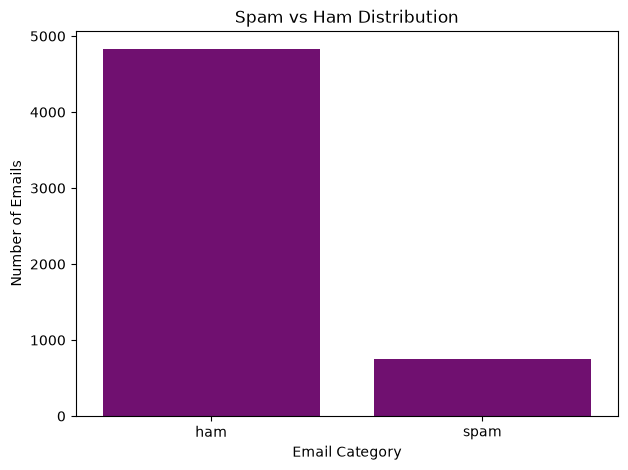

In [6]:
plt.figure(figsize=(7, 5))
sns.countplot(x="Category",data=raw_mail_data,color="purple")

plt.title("Spam vs Ham Distribution")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

In [7]:
raw_mail_data["Message_length"] = raw_mail_data["Message"].str.len()

Text(0, 0.5, 'Frequency')

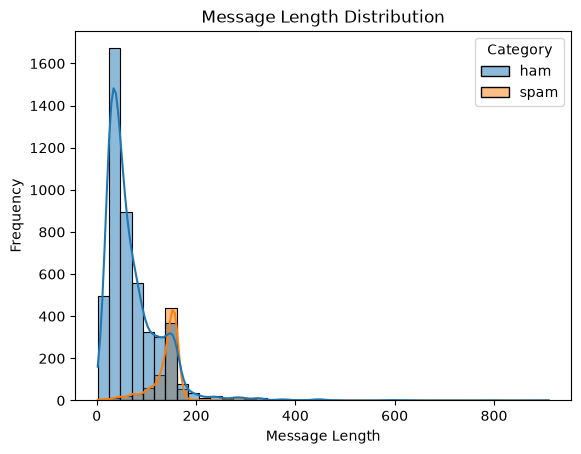

In [8]:
sns.histplot(
    data=raw_mail_data,
    x="Message_length",
    hue="Category",
    bins=40,
    kde=True

)

plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")


# Preprocessing Data #

In [9]:
X = raw_mail_data.drop("Category",axis=1)
y = raw_mail_data["Category"]

In [10]:
X

,Message,Message_length
0,"Go until jurong point, crazy.. Available only ...",111
1,Ok lar... Joking wif u oni...,29
2,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,U dun say so early hor... U c already then say...,49
4,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...
5567,This is the 2nd time we have tried 2 contact u...,160
5568,Will ü b going to esplanade fr home?,36
5569,"Pity, * was in mood for that. So...any other s...",57
5570,The guy did some bitching but I acted like i'd...,125


In [11]:
X["Message"] = X["Message"].str.lower()

In [12]:
print(X["Message"])

0       go until jurong point, crazy.. available only ...
1                           ok lar... joking wif u oni...
2       free entry in 2 a wkly comp to win fa cup fina...
3       u dun say so early hor... u c already then say...
4       nah i don't think he goes to usf, he lives aro...
                              ...                        
5567    this is the 2nd time we have tried 2 contact u...
5568                 will ü b going to esplanade fr home?
5569    pity, * was in mood for that. so...any other s...
5570    the guy did some bitching but i acted like i'd...
5571                           rofl. its true to its name
Name: Message, Length: 5572, dtype: str


In [13]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer       
from sklearn.preprocessing import StandardScaler      

preprocessor = ColumnTransformer (
    transformers =[
        ("text",CountVectorizer(),"Message"),
        ("length",StandardScaler(),["Message_length"])
    ]
)

In [15]:
X_train_features = preprocessor.fit_transform(X_train)
X_test_features = preprocessor.transform(X_test)

In [16]:
print(X_train_features[:5])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 93 stored elements and shape (5, 7702)>
  Coords	Values
  (0, 258)	1.0
  (0, 354)	1.0
  (0, 694)	1.0
  (0, 1271)	1.0
  (0, 2106)	1.0
  (0, 2568)	1.0
  (0, 2805)	1.0
  (0, 3364)	1.0
  (0, 5687)	1.0
  (0, 5980)	1.0
  (0, 5999)	1.0
  (0, 6460)	1.0
  (0, 6773)	1.0
  (0, 6888)	3.0
  (0, 7396)	1.0
  (0, 7437)	1.0
  (0, 7471)	1.0
  (0, 7474)	1.0
  (0, 7555)	1.0
  (0, 7701)	0.3789392799876211
  (1, 924)	1.0
  (1, 934)	1.0
  (1, 2395)	1.0
  (1, 2504)	1.0
  (1, 2627)	1.0
  :	:
  (4, 911)	1.0
  (4, 1509)	1.0
  (4, 1733)	1.0
  (4, 2485)	1.0
  (4, 2958)	1.0
  (4, 2993)	1.0
  (4, 3140)	1.0
  (4, 3387)	1.0
  (4, 3411)	1.0
  (4, 4898)	1.0
  (4, 4945)	1.0
  (4, 5172)	1.0
  (4, 5603)	1.0
  (4, 5687)	1.0
  (4, 5763)	2.0
  (4, 6460)	2.0
  (4, 6792)	1.0
  (4, 6857)	1.0
  (4, 6863)	1.0
  (4, 6888)	2.0
  (4, 7337)	1.0
  (4, 7393)	1.0
  (4, 7502)	1.0
  (4, 7662)	1.0
  (4, 7701)	1.2318171827951763


In [17]:
vectorizer = preprocessor.named_transformers_["text"]
words = vectorizer.get_feature_names_out()

print(words[924])
print(words[6888])

already
to


#  Logistic regression Model #

In [18]:
from sklearn.linear_model import LogisticRegression

LogisticRegressionModel = LogisticRegression(penalty='l2',solver='sag',C=1.0,random_state=33)
LogisticRegressionModel.fit(X_train_features, y_train)

y_pred = LogisticRegressionModel.predict(X_test_features)

c:\Users\YOUR\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\YOUR\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [19]:
from sklearn.metrics import accuracy_score , classification_report , confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9874439461883409

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.97      0.94      0.95       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115


Confusion Matrix:
[[961   5]
 [  9 140]]


# KNN Model #

In [20]:
from sklearn.neighbors import KNeighborsClassifier

KNNClassifierModel = KNeighborsClassifier(n_neighbors= 5,weights ='uniform', # it can be distance
                                          algorithm='auto') # it can be ball_tree, kd_tree,brute
KNNClassifierModel.fit(X_train_features, y_train)


y_pred = KNNClassifierModel.predict(X_test_features)

In [21]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9381165919282511

Classification Report:
              precision    recall  f1-score   support

         ham       0.93      1.00      0.97       966
        spam       1.00      0.54      0.70       149

    accuracy                           0.94      1115
   macro avg       0.97      0.77      0.83      1115
weighted avg       0.94      0.94      0.93      1115


Confusion Matrix:
[[966   0]
 [ 69  80]]


In [22]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(LogisticRegressionModel, "../models/spam_classifier.pkl")

joblib.dump(preprocessor, "../models/preprocessor.pkl")

['../models/preprocessor.pkl']

### 4 experiements ###
1. logisitic regression + countvectorize
2. logisitic regression + TF_IDF
3. Naive Byes + countvectorize
4. Naive Byes + TF_IDF

In [25]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score , classification_report , confusion_matrix

In [26]:
LR_model = LogisticRegression(random_state= 42)

NB_model = MultinomialNB()

In [27]:
count_vectorizer = CountVectorizer()
TFIDF_vectorizer = TfidfVectorizer()

In [44]:

def model_experiment(vectorizer , model , X_train , X_test , y_train ,  y_test):
    
    preprocessor = ColumnTransformer (
    transformers =[
        ("text",vectorizer,"Message"),
        ("length",MinMaxScaler(),["Message_length"])
    ])

    X_train_vec = preprocessor.fit_transform(X_train)
    X_test_vec = preprocessor.transform(X_test)
    
    model.fit(X_train_vec,y_train)
    y_pred = model.predict(X_test_vec)

    #evaluate
    report = classification_report(y_test, y_pred, output_dict=True)

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Spam Precision": report["spam"]["precision"],
        "Spam Recall": report["spam"]["recall"],
        "Spam F1-score": report["spam"]["f1-score"],
        "Model": model,
        "Preprocessor": preprocessor
    }
    




In [45]:
experiment={
    "count + LogisticRegression" :
    (CountVectorizer(),LogisticRegression()),

    "TFIDF + LogisticRegression" : 
    (TfidfVectorizer(),LogisticRegression()),

    "count + Naive Bayes" :
    (CountVectorizer(),MultinomialNB()),

    "TFIDF + Naive Byes" : 
   (TfidfVectorizer(),MultinomialNB())

}

In [46]:
results ={}
for name , (vectorizer , model) in experiment.items():
    scores = model_experiment(vectorizer , model ,X_train , X_test , y_train , y_test)

    results[name] = scores
results_df = pd.DataFrame(results)

print (results_df)

                                       count + LogisticRegression  \
Accuracy                                                 0.986547   
Spam Precision                                                1.0   
Spam Recall                                              0.899329   
Spam F1-score                                            0.946996   
Model                                        LogisticRegression()   
Preprocessor    ColumnTransformer(transformers=[('text', Count...   

                                       TFIDF + LogisticRegression  \
Accuracy                                                 0.976682   
Spam Precision                                                1.0   
Spam Recall                                              0.825503   
Spam F1-score                                            0.904412   
Model                                        LogisticRegression()   
Preprocessor    ColumnTransformer(transformers=[('text', Tfidf...   

                                

In [49]:
# the best model -> naive bayes + count vectorizer

best_preprocessor = results["count + Naive Bayes"]["Preprocessor"]
best_model = results["count + Naive Bayes"]["Model"]

In [50]:
import joblib
import os

joblib.dump(best_model, "../models/spam_classifier.pkl")

joblib.dump(best_preprocessor, "../models/preprocessor.pkl")

['../models/preprocessor.pkl']

In [51]:
print(type(best_model))
print(type(best_preprocessor))

print(best_preprocessor)

<class 'sklearn.naive_bayes.MultinomialNB'>
<class 'sklearn.compose._column_transformer.ColumnTransformer'>
ColumnTransformer(transformers=[('text', CountVectorizer(), 'Message'),
                                ('length', MinMaxScaler(), ['Message_length'])])
